# DX603 Final Project Milestone: Explore the Data Sets and Model Families

### Due Date: Sunday, November 15th at 11:59pm (with 2 hour plus 1 minute grace period)

**No late submissions!**

### What We Will Do in This Milestone

This milestone is the first stage of your final machine learning project. You will have **three weeks** to explore real-world data, prepare it for modeling, and investigate several approaches to prediction. We will follow a simplified version of the machine learning workflow developed throughout the course:

1. **Explore the data:** Investigate two datasets, identify important characteristics and challenges, and select one for your project.
2. **Prepare the data:** Clean the selected dataset, handle missing values and categorical features, and create training, validation, and test sets without data leakage.
3. **Establish a baseline:** Train and evaluate a linear or logistic regression model as a starting point.
4. **Experiment with features:** Conduct two distinct feature-engineering experiments to investigate how changes in the predictors affect performance.
5. **Compare model families:** Compare a linear or logistic model, a tree ensemble, and a feedforward neural network, and investigate how one change in model complexity affects performance.

The goal is not necessarily to obtain the best possible prediction at this stage, but to **develop a sound experimental workflow and understand how different modeling choices affect performance**.

In the final stage of the project, you will have another three weeks to build on this work with additional experiments, improve and select your models using validation results, evaluate your final model on the test set, and submit both a completed code notebook and a written report.

### The Datasets

You will explore two datasets and then choose **one** to use for the remainder of your project.

| Dataset | Prediction task | Target | Primary validation metric |
|---|---|---|---|
| **Zillow** | Regression: predict assessed property value | `taxvaluedollarcnt` | **MAE** (lower is better) |
| **Hotel Booking Demand** | Binary classification: predict booking cancellation | `is_canceled` (1 = canceled) | **F1** for predicting canceled bookings (higher is better) |

**Zillow:** This is a subset of the housing dataset used in the 2017 Zillow Prize competition on Kaggle. Your goal is to predict the assessed tax value of a property from a large collection of property descriptors. The data contains missing values, potentially redundant or irrelevant features, and outliers that make accurate prediction challenging.

**Hotel Booking Demand:** This dataset contains information about hotel reservations, including booking characteristics, guest information, and reservation details. Your goal is to predict whether a reservation will be canceled. In addition to the usual challenges of preparing real-world data, you will need to consider classification metrics and whether features would actually be available when making a prediction.

Neither dataset is preferred, and you will not be graded on which one you choose. **After Problem 1, use the same dataset for Problems 2–5 and for your final project.**

### How to Complete This Notebook

- Run the provided setup cells first. Complete the computational tasks using Python code, adding working code cells as needed.
- Write your reflections in the designated **Python answer variables**, using triple-quoted strings, as in the weekly homeworks. Use the exact variable names specified.
- **Do not modify the Graded Answer cells**, and be sure to run them before submitting.
- Base your conclusions on **your own computed results**. Keep relevant code, plots, outputs, and reflections visible in your submitted notebook.
- Use `random_state=42` where possible, document your modeling choices, and do not delete the provided task instructions.
- **Do not evaluate your models on the test set in this milestone.** You will reserve that evaluation for the final submission.

**Total: 100 points.**

In [1]:

# General utilities
import os
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

# Data splitting
from sklearn.model_selection import train_test_split

# Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer,
    PolynomialFeatures
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Models
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    median_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# TensorFlow / Keras setup
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
Available GPUs: []


## Setup and Dataset Loading

In Problem 1, you will explore two datasets before choosing one for the remainder of your project.

Run the setup cell below to load both datasets. If a dataset is already available locally, the code will use that copy. Otherwise, it will automatically download the dataset and save it for future use.

The original datasets will remain unchanged during Problem 1.

**Dataset Sources**

- **Zillow:** Course-provided housing dataset.
- **Hotel Booking Demand:** António, Almeida, and Nunes (2019). [Dataset on Kaggle](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand).

In [2]:

# Download a dataset only if it is not already available locally

def load_dataset(url):
    filename = os.path.basename(urlparse(url).path)

    if not os.path.exists(filename):
        try:
            print(f"Downloading {filename}...")
            response = requests.get(url, timeout=120)
            response.raise_for_status()
            with open(filename, "wb") as f:
                f.write(response.content)
            print("File downloaded successfully.")
        except requests.exceptions.RequestException as e:
            raise RuntimeError(
                f"Error downloading {filename}: {e}"
            ) from e
    else:
        print(f"{filename} already exists. Skipping download.")

    return pd.read_csv(filename)


# Zillow dataset
zillow_url = "https://www.cs.bu.edu/fac/snyder/cs505/Data/zillow_dataset.csv"
df_zillow = load_dataset(zillow_url)

# Hotel Booking Demand dataset
hotel_url = (
    "https://raw.githubusercontent.com/aaqibqadeer/"
    "Hotel-booking-demand/master/hotel_bookings.csv"
)
df_hotel = load_dataset(hotel_url)

print("\nDataset dimensions:")
print("Zillow:", df_zillow.shape)
print("Hotel Booking:", df_hotel.shape)


zillow_dataset.csv already exists. Skipping download.
hotel_bookings.csv already exists. Skipping download.

Dataset dimensions:
Zillow: (77613, 55)
Hotel Booking: (119390, 32)


## Problem 1 — Explore, Select, and Define a Prediction Task [15 points]

### Part A: Preliminary EDA of Both Datasets [10 points]

Before selecting a dataset for your project, conduct a brief exploratory analysis of **both** datasets, using the original dataframes `df_zillow` and `df_hotel`.

For each dataset:

**a. Dataset dimensions and types:** Report the number of observations, the number of predictors (excluding the target), and the number of columns currently stored as numerical and categorical. Remember that a column's data type does not necessarily reflect its meaning; for example, identifiers may be stored as integers.

**b. Target distribution:** Visualize the distribution of the target variable. For Zillow, include appropriate summary statistics for assessed property values. For Hotel Booking, report cancellation counts and percentages.

**c. Missing values:** Identify the five columns with the highest percentages of missing values (or all columns with missing values if fewer than five).

**d. Feature types:** Identify any high-cardinality categorical features or numeric-looking codes and identifiers that may require special handling during preprocessing.

**e. Data quality:** Describe one or two additional potential data-quality concerns you observe, explaining briefly why they might matter for modeling.

Keep this investigation focused. You do not need to plot every feature or perform any cleaning at this stage. The goal is to **understand the characteristics and challenges of each dataset before choosing one for your project.**

# <u> Zillow</u>

In [13]:
df_zillow.head()

,parcelid,airconditioningtypeid,architecturalstyletypeid,basementsqft,bathroomcnt,bedroomcnt,buildingclasstypeid,buildingqualitytypeid,calculatedbathnbr,decktypeid,...,yardbuildingsqft17,yardbuildingsqft26,yearbuilt,numberofstories,fireplaceflag,assessmentyear,taxdelinquencyflag,taxdelinquencyyear,censustractandblock,taxvaluedollarcnt
0,14297519,NaN,NaN,NaN,3.5,4.0,NaN,NaN,3.5,NaN,...,NaN,NaN,1998.0,NaN,NaN,2016.0,NaN,NaN,6.059063e+13,1023282.0
1,17052889,NaN,NaN,NaN,1.0,2.0,NaN,NaN,1.0,NaN,...,NaN,NaN,1967.0,1.0,NaN,2016.0,NaN,NaN,6.111001e+13,464000.0
2,14186244,NaN,NaN,NaN,2.0,3.0,NaN,NaN,2.0,NaN,...,NaN,NaN,1962.0,1.0,NaN,2016.0,NaN,NaN,6.059022e+13,564778.0
3,12177905,NaN,NaN,NaN,3.0,4.0,NaN,8.0,3.0,NaN,...,NaN,NaN,1970.0,NaN,NaN,2016.0,NaN,NaN,6.037300e+13,145143.0
4,10887214,1.0,NaN,NaN,3.0,3.0,NaN,8.0,3.0,NaN,...,NaN,NaN,1964.0,NaN,NaN,2016.0,NaN,NaN,6.037124e+13,119407.0


**1a**

In [ ]:
# Your code here; add as many cells as you wish
not_features = ['parcelid','taxvaluedollarcnt']

zil_numerical_columns = df_zillow.select_dtypes(include='number').drop(columns=not_features,errors='ignore').columns.to_list()
zil_categorical_columns = df_zillow.select_dtypes(include=['object']).drop(columns=not_features,errors='ignore').columns.to_list()

# 1a
print(f"# of Predictors (excl. Target & Identifier): {df_zillow.shape[1]-2}")
print(f"# of Numerical Columns                     : {len(zil_numerical_columns)}")
print(f"# of Categorical Columns                   : {len(zil_categorical_columns)}")

# of Predictors (excl. Target & Identifier): 53
# of Numerical Columns                     : 48
# of Categorical Columns                   : 5


**1b**

In [4]:
df_zillow['taxvaluedollarcnt'].describe()

count    7.757800e+04
mean     4.901506e+05
std      6.537979e+05
min      1.000000e+03
25%      2.068985e+05
50%      3.588785e+05
75%      5.690000e+05
max      4.906124e+07
Name: taxvaluedollarcnt, dtype: float64

Text(0.5, 1.0, 'Target Distribution (excl: top 1%)')

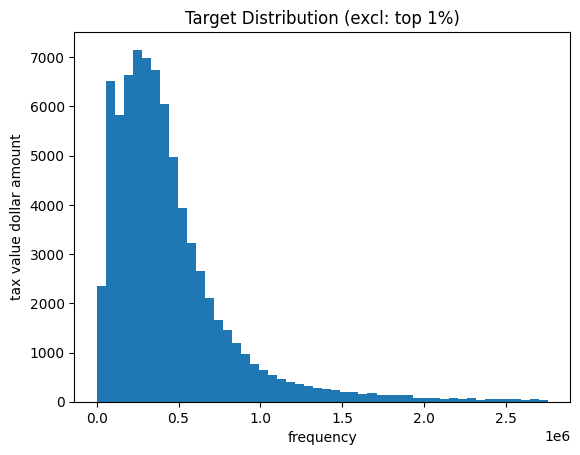

In [ ]:
# Top values are affecting data, using 99pct quantile to visualize distribution
s = df_zillow['taxvaluedollarcnt']
plt.hist(s[s < s.quantile(0.99)], bins=50)
plt.xlabel('frequency')
plt.ylabel('tax value dollar amount')
plt.title('Target Distribution (excl: top 1%)')

**1c**

In [ ]:
# Top 5 Columns with missing Data
zil_missing_df = pd.DataFrame({
    'total_rows'    : len(df_zillow),  
    'n_missing'     : df_zillow.isna().sum(),
    'pct_missing'   : (df_zillow.isna().mean() * 100).round(2)
}).sort_values('pct_missing', ascending=False).head(5)

zil_missing_df

,total_rows,n_missing,pct_missing
buildingclasstypeid,77613,77598,99.98
finishedsquarefeet13,77613,77571,99.95
basementsqft,77613,77563,99.94
storytypeid,77613,77563,99.94
yardbuildingsqft26,77613,77543,99.91


**1d**

In [ ]:
# High Cardinality within two of the categorical columns, might consider dropping for training as encoding them will create too many columns
card = df_zillow[zil_categorical_columns].nunique().sort_values(ascending=False)
card

propertyzoningdesc           1907
propertycountylandusecode      75
hashottuborspa                  1
fireplaceflag                   1
taxdelinquencyflag              1
dtype: int64

In [ ]:
# There are many numerical columns that might require processing to be come on hot encoded, as they should be categorical columns
num_card = df_zillow[zil_numerical_columns].nunique().sort_values(ascending=True)
num_card

decktypeid                          1
pooltypeid10                        1
pooltypeid7                         1
pooltypeid2                         1
poolcnt                             1
storytypeid                         1
assessmentyear                      1
buildingclasstypeid                 2
fips                                3
regionidcounty                      3
threequarterbathnbr                 4
numberofstories                     4
typeconstructiontypeid              4
airconditioningtypeid               5
fireplacecnt                        5
architecturalstyletypeid            5
unitcnt                             8
heatingorsystemtypeid              10
buildingqualitytypeid              12
taxdelinquencyyear                 13
fullbathcnt                        13
finishedsquarefeet13               13
propertylandusetypeid              13
garagecarcnt                       14
bedroomcnt                         16
roomcnt                            16
calculatedba

### Reflection 1.A — Preliminary Data Exploration

Compare the two datasets based on your preliminary EDA. 

> What did you learn about their target distributions, missing values, feature types, and potential data-quality problems?

Refer to specific results from your tables and plots. Identify the most important modeling challenges you anticipate for each dataset, and briefly explain why they might affect predictive performance.

Write **a coherent response of approximately 100–200 words** in `a1a`.

In [7]:
# Your answer here, NOT in the next cell

a1a = """
Write your reflection here.
"""

In [8]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1a = {a1a}")

a1a = 
Write your reflection here.



### Part B: Select One Dataset [5 points]

Choose **Zillow** or **Hotel Booking** as the dataset for your final project.

Base your decision on your preliminary EDA, your interest in the prediction task, and the modeling challenges you identified.

Record your selection in `a1_dataset`, using exactly `"Zillow"` or `"Hotel Booking"`.

**Your choice itself is not graded.** You will use this dataset for the remainder of the milestone and the final project.

In [9]:
# Select your dataset: "Zillow" or "Hotel Booking"

a1_dataset = ""  # "Zillow" or "Hotel Booking"

In [10]:
# Dataset selection and setup
# DO NOT change this cell

assert a1_dataset in ("Zillow", "Hotel Booking"), \
    "Choose exactly 'Zillow' or 'Hotel Booking'."

if a1_dataset == "Zillow":
    selected_raw = df_zillow.copy()
    target = "taxvaluedollarcnt"
    task = "regression"
else:
    selected_raw = df_hotel.copy()
    target = "is_canceled"
    task = "classification"

print("Selected dataset:", a1_dataset, "(stored in selected_raw)")
print("Prediction task:", task)
print("Target:", target)
print("Dataset shape:", selected_raw.shape)

AssertionError: Choose exactly 'Zillow' or 'Hotel Booking'.

### Reflection 1.B — Dataset Selection

Explain why you selected this dataset. What attracts you to its prediction task?

> 1. Identify **two specific modeling challenges** revealed by your preliminary EDA,
> 2. Explain how they might affect your approach, and
> 3. Identify **one interesting challenge** in the dataset you did not choose.

Support your discussion with observations from Problem 1.A.

Write **a coherent response of approximately 100–150 words** in `a1b`.

In [ ]:
# Your answer here, NOT in the next cell

a1b = """
Write your reflection here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1b = {a1b}")

a1b = 
Write your reflection here.



## Problem 2 — Clean and Prepare Your Selected Dataset [20 points]

In this problem, you will prepare **only the dataset you selected in Problem 1** for modeling. Your goal is to construct a reproducible preprocessing workflow that can be reused throughout the milestone and final project.

Make cleaning decisions based on your preliminary EDA. In particular, consider **which predictors would actually be available at prediction time**. Any preprocessing steps that learn from the data (such as imputation, scaling, and encoding) must be fitted on **training data only**.

**Do not train models or evaluate test-set performance in this problem.**

### Part A: Examine the Data and Plan Cleaning [5 points]

Starting with `selected_raw` from Problem 1:

1. Report the number of rows and columns, the number of missing target values, and the number of exact duplicate rows. Do not assume that every duplicate is an error.
2. Identify important predictors with missing values, numeric-looking categorical codes or identifiers, and any other features requiring special attention.
3. Identify **at least two specific cleaning decisions**, including **one concerning whether a feature would be available at prediction time**. For Hotel Booking, consider what is known when a reservation is made; for Zillow, consider whether a feature directly reveals or postdates the assessed value.

Present your findings using appropriate tables or summary statistics. Use additional code cells as needed to investigate potential problems. **Do not perform any cleaning or fit any preprocessing transformations yet.**

In [ ]:
# Your code here; add additional cells as needed


### Reflection 2.A — Data Quality and Leakage

Based on your preliminary investigation of the selected dataset:

1. Explain **at least two specific cleaning or feature-selection decisions** you plan to make, and justify them using your findings.
2. For at least one decision, discuss whether the relevant information would actually be available at prediction time and how this affects your choice.
3. Explain how you plan to handle numeric-looking categorical codes or identifiers, if present.

Support your discussion with specific observations from your investigation.

Write **a coherent response of approximately 100–150 words** in `a2a`.

In [ ]:
# Your answer here, NOT in the next cell

a2a = """
Write your reflection here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2a = {a2a}")

a2a = 
Write your reflection here.



### Part B: Clean the Rows and Create Data Splits [4 points]

Using `selected_raw`, carry out only the row-level cleaning decisions justified by your investigation (for example, handling missing target values or confirmed duplicate errors). **Do not impute predictors, scale features, or encode categories before splitting.**

1. Separate the target (`target`) from the predictors. Remove predictors that should not be available at prediction time and any columns you decided to exclude. Keep track of the columns you remove and why.
2. Create **training (80%), validation (10%), and test (10%)** partitions, using `random_state=42`. For Hotel Booking, stratify by the target so the cancellation proportions remain similar across the partitions, where feasible.
3. Store the partitions in **`X_train`, `X_val`, `X_test`, `y_train`, `y_val`, and `y_test`**. Report their dimensions and, for Hotel Booking, the cancellation percentages in each partition.

Do not inspect the test set to make modeling decisions, and **do not evaluate any models on the test set**. Keep it untouched for the final submission.

In [ ]:
# Your code here; add additional cells as needed

### Reflection 2.B — Data Cleaning and Splitting

1. Describe the row-level cleaning and feature-removal decisions you made. Explain why these choices were appropriate for your selected prediction task.
2. Explain why the split must precede any preprocessing step that learns from the data, such as imputation or scaling.
3. For Hotel Booking, explain the role of stratification; for Zillow, comment on any important distributional concerns that remain after the split.

Refer to your results and split summary.

Write **a coherent response of approximately 100–150 words** in `a2b`.

In [ ]:
# Your answer here, NOT in the next cell

a2b = """
Write your reflection here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2b = {a2b}")

a2b = 
Write your reflection here.



### Part C: Build a Reusable Preprocessing Workflow [5 points]

Create a **scikit-learn preprocessing workflow** that can be used with each of the three model families in later problems.

1. Identify numerical and categorical predictor columns from `X_train`. Treat numeric-looking identifiers and categorical codes according to their meaning, not merely their stored data type.
2. Define appropriate preprocessing steps for each type of predictor:
   - **Numerical features:** Handle missing values using imputation and apply scaling where appropriate.
   - **Categorical features:** Handle missing values and use one-hot encoding to convert categories into numerical representations.
3. Use scikit-learn's **`Pipeline`** to organize the numerical and categorical preprocessing steps, and **`ColumnTransformer`** to combine them into a single preprocessing workflow named `preprocessor`.

**Define but do not fit `preprocessor` in this part.** In Problem 3, it will be fitted as part of a model pipeline using only the training data. Do not fit preprocessing transformations on the validation or test sets, or transform all three partitions in advance.

In [ ]:
# Your code here; add additional cells as needed



### Reflection 2.C — Preprocessing Choices

1. Justify your decisions for missing values, categorical encoding, and numerical scaling.
2. Explain how you handled any categorical codes, identifiers, or high-cardinality features.
3. Explain how your workflow avoids learning preprocessing parameters from validation or test data.

Connect your choices to characteristics of the selected dataset.

Write **a coherent response of approximately 100–150 words** in `a2c`.

In [ ]:
# Your answer here, NOT in the next cell

a2c = """
Write your reflection here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2c = {a2c}")

a2c = 
Write your reflection here.



### Part D: Verify the Splits and Preprocessing Design [4 points]

Before modeling, verify that the outputs of Parts B and C are consistent and ready for use in the baseline model.

1. Confirm that the training, validation, and test partitions have the same predictor columns in the same order, and that each feature matrix has the corresponding number of target values.
2. Check that the target values are appropriate for your prediction task and that the predictors do not contain the target or any known sources of prediction-time leakage.
3. Verify that `preprocessor` contains the intended numerical and categorical transformations and references columns that exist in `X_train`. **Do not fit the preprocessor yet.**
4. Summarize the checks performed and identify any problems you found and corrected.

Use clear print statements or a small results table. Avoid displaying large data matrices.

In [ ]:
# Your code here; add additional cells as needed


### Reflection 2.D — Verifying Data Preparation

1. What evidence shows that the data splits and feature columns are ready for modeling?
2. Did the checks reveal any problems? If so, explain what you changed; if not, identify one potential preprocessing failure your checks were designed to catch.
3. Explain why this kind of verification matters before comparing different models.

Write **a coherent response of approximately 75–125 words** in `a2d`.

In [ ]:
# Your answer here, NOT in the next cell

a2d = """
Write your reflection here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2d = {a2d}")

a2d = 
Write your reflection here.



### Part E: Ready for Modeling [2 points]

Before proceeding to Problem 3, summarize the data and preprocessing workflow you have prepared.

1. Display the selected prediction task, target variable, number of predictor columns, and sizes of the training, validation, and test sets.
2. Confirm that `X_train`, `X_val`, `X_test`, `y_train`, `y_val`, `y_test`, and the **unfitted** `preprocessor` are ready for modeling.
3. Identify the primary validation metric you will use: **MAE** for Zillow or **F1** for the cancellation class (`1`) for Hotel Booking.

**Do not train a model or evaluate performance on the test set.**

> Grading: The 2 points for this part will be awarded based on your code and its output. No separate reflection or answer variable is required.

In [ ]:
# Your code here; add additional cells as needed



## Problem 3 — Establish a Baseline Model [20 points]

In this problem, you will establish an initial predictive model for the dataset selected in Problem 1. Use the **training and validation partitions** and the `preprocessor` developed in Problem 2, combining preprocessing and modeling in a scikit-learn `Pipeline`.

The objective is to establish a clear, reproducible point of comparison for the experiments that follow, **not to optimize performance yet**.

- **Zillow:** Train a linear regression model and evaluate it using **MAE** (lower is better).
- **Hotel Booking:** Train a logistic regression model and evaluate it using **F1 for the cancellation class (`1`)** (higher is better).

Use the same training/validation split and primary evaluation metric throughout the remaining milestone. You may report additional metrics to help interpret model behavior.

**Do not use the test set in this milestone.**

### Part A: Train a Baseline Model [10 points]

Build and evaluate an initial model using the preprocessing workflow from Problem 2.

1. Construct a **scikit-learn `Pipeline`** that combines your `preprocessor` with the appropriate estimator:
   - **Zillow:** `LinearRegression`
   - **Hotel Booking:** `LogisticRegression`
2. Fit the pipeline using **`X_train` and `y_train` only**. Generate predictions for both the training and validation sets.
3. Evaluate the model on both partitions using the primary metric:
   - **Zillow:** Mean Absolute Error (MAE).
   - **Hotel Booking:** F1 for the cancellation class (`1`), using the default classification threshold of 0.5. Also report the number of predicted cancellations on each partition.
4. Present the training and validation results in a small, clearly labeled table. Save the fitted pipeline as `baseline_model` for use in subsequent problems.

You may add code cells as needed. **Do not tune hyperparameters or modify the preprocessing workflow yet. Do not use the test set.**

In [ ]:
# Your code here; add additional cells as needed.
# Use X_train, X_val, y_train, y_val, preprocessor, and task
# from earlier problems.
# Save your fitted pipeline as baseline_model.



### Reflection 3.A — Initial Baseline Results

Interpret the training and validation results for your baseline model.

1. How well does the model perform on the validation set, using your dataset's primary metric? Cite your **actual metric values** and explain what they mean in the context of the prediction task.
2. How does training performance compare with validation performance? What does that comparison suggest, and what can it *not* establish by itself?
3. Identify one plausible limitation of this baseline that you may want to investigate later.

Write **a coherent response of approximately 100–150 words** in `a3a`.

In [ ]:
# Your answer here, NOT in the next cell

a3a = """
Write your reflection here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3a = {a3a}")

a3a = 
Write your reflection here.



### Part B: Examine the Model's Predictions [10 points]

Go beyond the overall performance metric to investigate **how and where your baseline model makes errors** on the validation set.

Complete the analysis appropriate to your selected dataset:

**Zillow (Regression)**

1. Examine the distribution of prediction errors and identify whether some properties have unusually large errors.
2. Create at least one informative plot, such as predicted vs. actual values or residuals vs. predictions. Look for patterns that might reveal weaknesses in the model.
3. Report an additional measure of error, such as the median absolute error, to complement MAE.

**Hotel Booking (Classification)**

1. Display the confusion matrix for the validation predictions.
2. Report precision and recall for the cancellation class (`1`), in addition to the F1 score calculated in Part A.
3. Explain what false positives and false negatives mean in the booking context, and investigate which type of error occurs more frequently.

Use appropriate plots and numerical summaries to support your analysis.

**Do not modify the baseline model or evaluate performance on the test set.**

In [ ]:
# Your code here; add additional cells as needed


### Reflection 3.B — What the Baseline Misses

Based on your validation-set diagnostics:

1. Identify the **most important pattern or limitation** you observed in the baseline's predictions, citing at least one numerical result or plot.
2. Explain why this matters for the underlying prediction task.
3. Propose **one specific improvement or experiment** to investigate in Problems 4 or 5 that might address this limitation. Explain why you think it could help and what you expect to learn.

Write **a coherent response of approximately 100–150 words** in `a3b`.

In [ ]:
# Your answer here, NOT in the next cell

a3b = """
Write your reflection here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3b = {a3b}")

a3b = 
Write your reflection here.



## Problem 4 — Feature Engineering Experiments [20 points]

In Problem 3, you established a baseline model using your original feature representation. In this problem, investigate whether changes to the predictor features improve validation performance.

Conduct **two distinct, hypothesis-driven feature-engineering experiments**. For each experiment, explain why the proposed change might help, implement it, and compare its results with the **unchanged baseline** from Problem 3.

- **Zillow:** Continue using `LinearRegression` and validation MAE (lower is better).
- **Hotel Booking:** Continue using `LogisticRegression` and validation F1 for cancellation class `1` (higher is better), with the default 0.5 classification threshold.

Keep the same training/validation partitions and baseline estimator settings. **Evaluate each change independently against the original baseline**, not cumulatively. Do not tune model hyperparameters or use the test set. Any transformations that learn parameters from the data must be fitted using training data only.

### Part A: Design and Evaluate Two Feature-Engineering Experiments [12 points]

Develop **two different feature-engineering changes** motivated by what you learned in Problems 1–3. Examples include a meaningful derived feature, a transformation of a skewed numerical predictor, or a different representation of an existing predictor. Choose changes appropriate to your dataset; do not simply remove predictors at random.

For each experiment:

1. State a specific **hypothesis**: what feature representation will you change, and why might it improve predictions?
2. Implement the change in a **reproducible, leakage-free workflow**. Apply the same feature definitions to training and validation data, fitting any learned transformations using training data only. Do not use validation performance to determine transformation parameters.
3. **Train a new model** using the same estimator type and hyperparameter settings as the original baseline, but with the modified feature representation. Generate training and validation predictions. Do not modify or overwrite `baseline_model`.
4. Report the **training and validation primary metric** for the experiment. Compare its validation score with the original baseline.

Present a compact results table with rows for **Baseline**, **Experiment 1**, and **Experiment 2**, including the feature change and both metric values. Keep code and plots necessary to understand the experiments visible in the notebook.

**Important:** Start each experiment from the original Problem 3 feature set and preprocessing design, making only that experiment's proposed change. Do not combine the two changes in this milestone.

**An experiment is not considered unsuccessful simply because validation performance fails to improve.** What matters is that you test a reasonable hypothesis, evaluate it correctly, and interpret the results.

In [ ]:
# Your code here; add additional cells as needed.
# Implement and evaluate two independent feature-engineering experiments.
# Keep baseline_model unchanged and compare both experiments against it.



### Reflection 4.A — Feature-Engineering Hypotheses and Results

For each of your two experiments:

1. Describe the feature change and **why you expected it to help**, connecting your hypothesis to characteristics of the dataset or the baseline's errors.
2. Report the **actual training and validation metric values** and quantify the change in validation performance relative to the original baseline.
3. Explain whether the result supports your hypothesis, what you learned from it, and identify one possible limitation of the experiment.

Write **a coherent response of approximately 150–200 words** in `a4a`.

In [ ]:
# Your answer here, NOT in the next cell

a4a = """
Write your reflection here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4a = {a4a}")

a4a = 
Write your reflection here.



### Part B: Compare the Experiments and Draw Conclusions [8 points]

Use your results from Part A to compare the two feature-engineering experiments and determine what they reveal about your selected prediction task.

1. **Compare all three feature representations**—the original baseline and both experiments. Identify which achieved the best validation performance and quantify its improvement or decline relative to the baseline.
2. Investigate **at least one difference beyond the primary validation metric**. For example, compare training–validation gaps, examine whether a particular error pattern improved, or investigate another relevant diagnostic measure. Support your analysis with a small table or plot.
3. Based on your findings, identify which feature changes, if any, you would consider carrying forward to the final project. Explain what additional experiments or evidence would help you decide.

**Do not combine the feature changes, tune hyperparameters, or evaluate on the test set.**

In [ ]:
# Your code here; add additional cells as needed.
# Compare the baseline and both feature-engineering experiments.



### Reflection 4.B — What Did Feature Engineering Teach You?

1. Considering all three feature representations, what is your **overall conclusion** about the value of your feature-engineering experiments? Were the differences in validation performance large enough to be practically meaningful?
2. What did your additional diagnostic comparison reveal that the primary validation metric alone would not show?
3. Which feature changes, if any, would you consider carrying forward to the final project? Explain your reasoning and identify one important question that remains unanswered.

Support your conclusions with specific evidence from your results.

Write **a coherent response of approximately 100–150 words** in `a4b`.

In [ ]:
# Your answer here, NOT in the next cell

a4b = """
Write your reflection here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4b = {a4b}")

a4b = 
Write your reflection here.



## Problem 5 — Compare Model Families [25 points]

In Problem 3, you established a linear or logistic regression baseline. In this problem, compare that baseline with a **tree ensemble** and a **feedforward neural network** to investigate how different model families perform on your selected prediction task.

Use the **original predictor representation from Problem 3**, not either feature-engineering experiment from Problem 4. Keep the same training/validation partitions and primary validation metric:

- **Zillow:** MAE (lower is better).
- **Hotel Booking:** F1 score for predicting canceled bookings (`is_canceled` = 1), with a classification threshold of 0.5.

Focus on a **fair initial comparison**, not an exhaustive search for the highest score. Fit all model parameters and learned preprocessing transformations using **training data only**. You may use validation data to evaluate and compare models, but **do not use the test set in this milestone**.

### Part A: Train and Compare Three Model Families [15 points]

Compare the fitted `baseline_model` from Problem 3 against **two new models**:

1. **Tree ensemble:** Train a `RandomForestRegressor` for Zillow or a `RandomForestClassifier` for Hotel Booking. Choose reasonable initial hyperparameter settings, including `random_state=42`. Do not perform a hyperparameter search.
2. **Feedforward neural network:** Build a modest Keras network with one or two hidden `Dense` layers and an appropriate output layer and loss function for your task. Set a random seed and use a fixed initial training configuration. Do not perform a hyperparameter search.
3. **Consistent evaluation:** Train both new models using the original Problem 3 predictor information and the same training partition. Fit all preprocessing transformations using training data only. You may adapt preprocessing to the needs of each model family (for example, numerical scaling or conversion to dense arrays), but **do not add or remove predictive features**.
4. **Compare results:** Report the training and validation primary metric for all three model families: the original baseline, the random forest, and the neural network. For Hotel Booking, use the same **0.5 classification threshold** for all models. Present the results in a compact, clearly labeled comparison table.

Retain the fitted models and preprocessing required to reproduce their predictions. You may include a neural-network learning curve if it helps explain the results.

**Choose initial model settings, train each new model once, and report the results without further tuning.** More systematic experimentation and optimization will take place in the final project. Do not use the modified feature representations from Problem 4 or evaluate on `X_test`.

In [ ]:
# Your code here; add additional cells as needed.
# Compare baseline_model with a random forest and a feedforward neural network.
# Use the original Problem 3 features and the same train/validation split.
# Report training and validation metrics for all three models.



### Reflection 5.A — Comparing Model Families

1. Compare the training and validation results for all three model families, citing **specific metric values** from your results table. Which model performed best on the validation set, and by how much relative to the baseline?
2. What evidence, if any, suggests underfitting or overfitting? Explain why **better training performance does not necessarily mean better generalization**.
3. Discuss one practical tradeoff among the model families, such as interpretability, training complexity, or sensitivity to preprocessing.

Base your discussion on your own results. Write **a coherent response of approximately 150–200 words** in `a5a`.

In [ ]:
# Your answer here, NOT in the next cell

a5a = """
Write your reflection here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a5a = {a5a}")

a5a = 
Write your reflection here.



### Part B: Investigate Model Complexity and Draw Conclusions [10 points]

Choose **one** of the two new model families (random forest or neural network) and conduct **one controlled experiment** to investigate model complexity.

1. State a hypothesis about how **one complexity-related setting** might influence training and validation performance. Examples include `max_depth` for the random forest or the number of units in a neural-network hidden layer.
2. Starting with the model configuration used in Part A, train **one additional version** of the selected model, changing **only the chosen complexity setting**. Keep the same features, data partitions, evaluation metric, and other model settings. Fit preprocessing transformations using training data only, and use `random_state=42` or the same Keras seed where applicable.
3. Compare the **original and modified versions** using both training and validation performance. Display a compact table or plot showing the effect of the change.
4. Based on all your results from Problem 5, identify which model family appears most promising for further investigation in the **final project**. Explain your choice and propose one additional experiment or question worth pursuing during the final three weeks.

Your goal is to understand the **effect of a controlled change**, not necessarily to improve performance. **Do not perform grid search, evaluate on the test set, or claim that a single validation result establishes which model will generalize best.**

In [ ]:
# Your code here; add additional cells as needed.
# Change one complexity-related setting in either the random forest or neural network.
# Compare its training and validation performance with the original version.



### Reflection 5.B — Complexity and Next Steps

1. What complexity setting did you change, and why did you expect it to affect model behavior?
2. Report the **actual training and validation results** before and after the change. What do these results suggest about the relationship between model complexity, overfitting or underfitting, and generalization?
3. Based on the model-family comparisons and this experiment, which approach would you investigate further in the final project? Explain your choice and identify one important uncertainty that remains.

Support your conclusions with specific results. Write **a coherent response of approximately 125–175 words** in `a5b`.

In [ ]:
# Your answer here, NOT in the next cell

a5b = """
Write your reflection here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a5b = {a5b}")

a5b = 
Write your reflection here.



## Submission Checklist

Before submitting your milestone notebook to Gradescope, verify the following:

-  **All five problems are complete**, including the required code, tables, plots, and reflections.
-  You explored both datasets in Problem 1 and used your selected dataset consistently throughout Problems 2–5.
-  Your training, validation, and test partitions are correctly defined, and all learned preprocessing transformations were fitted using training data only.
-  You evaluated the baseline, feature-engineering experiments, and three model families using the required validation metric.
-  **You did not evaluate any model on the test set.** The test set is reserved for the final project.
-  All reflection variables (`a1a`, `a1b`, `a2a`–`a2d`, `a3a`, `a3b`, `a4a`, `a4b`, `a5a`, `a5b`) contain your own substantive answers.
-  You ran all the **Graded Answer** cells without modifying them.
-  You restarted the kernel and ran the entire notebook from beginning to end without errors.
-  All relevant code output, tables, and plots are visible in the submitted notebook.

**Submit your completed `.ipynb` file to Gradescope.** Do not submit the datasets or any additional files.

**Due: Sunday, November 15th at 11:59 PM**, with a 2-hour and 1-minute grace period. 

**No late submissions -- We have to start grading immediately!**